# **실습 개요**

여러분은 한국은행(가상) 화폐 감식팀에 합류한 데이터 분석가입니다.<br>
지폐 스캐너로 촬영한 이미지를 웨이블릿 변환(Wavelet Transform)하여 얻은 통계적 특징만으로 <br>
**진짜 지폐와 위조 지폐를 자동으로 구분**하는 모델을 만들어 달라는 요청을 받았습니다.

스캐너 장비 특성상 일부 측정값에는 결측치가 있고, 장비 오작동으로 인한 이상치, 중복 스캔 데이터도 섞여 있습니다. <br>
이 데이터를 정제하고 **PyTorch `nn.Module` 기반의 이진 분류 신경망**을 학습시켜, 새로운 지폐의 진위 여부를 예측해봅시다.

## **데이터셋 설명**

지폐 이미지를 웨이블릿 변환하여 추출한 통계적 특징 데이터입니다.

| 컬럼명 | 설명 |
|---|---|
| note_id | 지폐 스캔 고유 ID |
| wavelet_variance | 웨이블릿 변환 이미지의 분산 (값의 퍼짐 정도) |
| wavelet_skewness | 웨이블릿 변환 이미지의 왜도 (비대칭 정도) |
| wavelet_curtosis | 웨이블릿 변환 이미지의 첨도 (뾰족한 정도) |
| image_entropy | 이미지의 엔트로피 (무질서도) |
| is_forged | **[target]** 위조 지폐 여부 (0 = 진짜, 1 = 위조) |

## **데이터셋 URL**

https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/banknote_forgery.csv

---
## **1. 데이터 살펴보기**

데이터를 불러오고, 각 컬럼이 어떤 의미를 갖는지, 데이터의 전체적인 형태가 어떤지 살펴봅니다.

**Q1. 필요한 라이브러리를 불러오고, 데이터를 불러온 뒤 첫 5개의 행을 출력하세요.**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn

df = pd.read_csv("https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/banknote_forgery.csv")
df.head()

,note_id,wavelet_variance,wavelet_skewness,wavelet_curtosis,image_entropy,is_forged
0,1475,-0.7869,9.5663,-3.7867,-7.5034,0
1,2272,4.3239,-4.8835,3.4356,-0.5776,0
2,1867,-2.4953,11.1472,1.9353,-3.4638,0
3,1270,-1.6386,3.3584,-1.7302,NaN,1
4,2224,-2.5373,-6.9590,8.8054,1.5289,1


**Q2. 데이터의 전체적인 구조를 확인하세요.**

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1312 entries, 0 to 1311
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   note_id           1312 non-null   int64  
 1   wavelet_variance  1260 non-null   float64
 2   wavelet_skewness  1221 non-null   float64
 3   wavelet_curtosis  1273 non-null   float64
 4   image_entropy     1181 non-null   float64
 5   is_forged         1312 non-null   int64  
dtypes: float64(4), int64(2)
memory usage: 61.6 KB


**Q3. 데이터의 수치형 컬럼들의 기초 통계량을 확인하세요.**

In [3]:
df.describe()

,note_id,wavelet_variance,wavelet_skewness,wavelet_curtosis,image_entropy,is_forged
count,1312.000000,1260.000000,1221.000000,1273.000000,1181.000000,1312.000000
mean,2645.944360,0.385652,1.983439,1.179265,-1.187992,0.445122
std,9405.564474,3.453177,7.043693,5.415791,2.770070,0.497169
min,1001.000000,-22.001136,-44.960751,-39.347403,-19.909607,0.000000
25%,1324.750000,-1.798950,-1.705100,-1.730200,-2.456500,0.000000
50%,1641.500000,0.455130,2.330000,0.555800,-0.582770,0.000000
75%,1962.250000,2.853250,6.816200,3.089500,0.407740,1.000000
max,90014.000000,21.861281,43.292908,39.539183,19.429515,1.000000


## **3. 데이터 전처리하기**

### **3.1 중복 행 제거하기**

**Q1. note_id를 제외한 특징들의 값이 완전히 동일한 중복 행의 개수를 찾아보세요.**

In [4]:
dup_cols = df.drop("note_id", axis=1).columns
print(dup_cols)

Index(['wavelet_variance', 'wavelet_skewness', 'wavelet_curtosis',
       'image_entropy', 'is_forged'],
      dtype='str')


In [5]:
n_dup = df.duplicated(subset=dup_cols).sum()
print(n_dup)

32


**Q2. note_id를 제외한 특징들의 값이 완전히 동일한 중복 행들을 삭제해 주세요.**

In [6]:
df = df.drop_duplicates(subset=dup_cols)
df.shape

(1280, 6)

In [7]:
df.head()

,note_id,wavelet_variance,wavelet_skewness,wavelet_curtosis,image_entropy,is_forged
0,1475,-0.7869,9.5663,-3.7867,-7.5034,0
1,2272,4.3239,-4.8835,3.4356,-0.5776,0
2,1867,-2.4953,11.1472,1.9353,-3.4638,0
3,1270,-1.6386,3.3584,-1.7302,NaN,1
4,2224,-2.5373,-6.9590,8.8054,1.5289,1


### **3.2 데이터 분리하기**

**Q1. 학습 데이터와 테스트 데이터를 분리한다.**

- note_id를 제외한 수치형 컬럼을 X, is_forged 컬럼을 y로 지정한다.
- test 데이터의 비율은 30%로 한다.
- 재현성을 위해 random_state=42로 설정한다.

In [8]:
from sklearn.model_selection import train_test_split

columns = ["wavelet_variance", "wavelet_skewness", "wavelet_curtosis", "image_entropy"]

X = df[columns]
y = df["is_forged"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
X_train.head()

,wavelet_variance,wavelet_skewness,wavelet_curtosis,image_entropy
136,NaN,0.084831,-0.24620,0.45688
312,-0.36372,3.043900,-3.48160,-2.78360
1091,1.27460,8.817200,NaN,-1.79570
857,-7.03640,9.293100,0.16594,-4.53960
1217,2.09220,-6.810000,8.46360,-0.60216


### **3.3 결측치 처리**

**Q1. 각 컬럼별 결측치의 개수를 확인해봅시다.**

In [9]:
X_train.isnull().sum()

wavelet_variance    33
wavelet_skewness    60
wavelet_curtosis    25
image_entropy       98
dtype: int64

**Q2. 각 컬럼들의 결측치를 중앙값(median)으로 채우세요.**

- 테스트 데이터의 결측치도 학습 데이터의 median으로 채워줘야 data leakage를 방지할 수 있습니다.

In [10]:
X_train = X_train.copy()
X_test = X_test.copy()

for col in columns:
    median_val = X_train[col].median()
    X_train[col] = X_train[col].fillna(median_val)
    X_test[col] = X_test[col].fillna(median_val)

### **3.4 이상치 처리**

**Q1. IQR을 활용해서 각 컬럼에 총 몇개의 이상치가 있는지를 확인해보자.**

In [11]:
def find_whiskers(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    iqr = Q3 - Q1
    lower = Q1 - 1.5 * iqr
    upper = Q3 + 1.5 * iqr
    return lower, upper

In [12]:
d = {}
for c in X_train.columns:
    if X_train[c].dtype == "object" or X_train[c].dtype == "bool": continue
    lower, upper = find_whiskers(X_train, c)
    print(c, ":", ((X_train[c] < lower) | (X_train[c] > upper)).sum())
    d[c] = [lower, upper]

wavelet_variance : 8
wavelet_skewness : 20
wavelet_curtosis : 42
image_entropy : 48


**Q2. 이상치를 처리합니다.**

- 각 특징 컬럼의 값을 [Q1 - 1.5 * IQR, Q3 + 1.5 * IQR] 범위로 clipping(capping)하세요.

In [13]:
for c in X_train.columns:
    if X_train[c].dtype == "object" or X_train[c].dtype == "bool": continue
    lower, upper = find_whiskers(X_train, c)
    X_train[c] = X_train[c].clip(lower, upper)
    X_test[c] = X_test[c].clip(lower, upper)

### **3.5 스케일링**

**Q1. 각 특징을 표준화(StandardScaler)합니다.**

  - 신경망은 각 특징의 scale에 매우 민감하므로, 반드시 포함해야 하는 전처리 단계입니다.

In [14]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

### **3.6 PyTorch Tensor 변환**

PyTorch 모델은 NumPy 배열이 아닌 **Tensor**를 입력으로 받습니다.

| 용도 | dtype 이유 |
|---|---|
| X (특징) | `float32` — 신경망 가중치 연산 기본 타입 |
| y (레이블) | `float32` — `BCELoss`가 float 입력을 요구 |

**Q1. 각 학습, 테스트 데이터를 tensor로 변환합니다.**

- dtype = float32로 설정합니다.
- 라벨 (y_train, y_test)의 shape는 반드시 (N, 1)의 형태가 되도록 형태 변환을 해주세요.

In [ ]:
print(type(X_train_scaled), type(y_train))
# <class 'numpy.ndarray'> <class 'pandas.Series'>

X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
X_test_tensor  = torch.tensor(X_test_scaled, dtype=torch.float32)

y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32).reshape(-1, 1)
y_test_tensor  = torch.tensor(y_test.values, dtype=torch.float32).reshape(-1, 1)

print(X_train_tensor.shape, y_train_tensor.shape)

<class 'numpy.ndarray'> <class 'pandas.Series'>
torch.Size([896, 4]) torch.Size([896, 1])


## **4. 모델 정의 (nn.Module)**

**Q1. 아래 구조를 참고해 MLP 클래스와 forward()를 완성하세요.**

```
입력(4) → Linear(4→8) → ReLU → Linear(8→1) → Sigmoid
```

In [16]:
import torch.nn as nn

class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear1 = nn.Linear(4, 8)
        self.relu = nn.ReLU()
        self.linear2 = nn.Linear(8, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, X):
        z1 = self.linear1(X)
        a1 = self.relu(z1)
        z2 = self.linear2(a1)
        a2 = self.sigmoid(z2)
        return a2

**Q2. 모델을 생성하고 출력하여 layer를 확인해주세요.**

In [17]:
model = MLP()
print(model)

MLP(
  (linear1): Linear(in_features=4, out_features=8, bias=True)
  (relu): ReLU()
  (linear2): Linear(in_features=8, out_features=1, bias=True)
  (sigmoid): Sigmoid()
)


## **5. 모델 학습**

### **5.1 손실 함수**

**Q1. 이진 분류를 위한 BCELoss로 criterion을 설정해주세요.**

In [18]:
criterion = nn.BCELoss()

### **5.2 옵티마이저**

**Q1. 옵티마이저로 Adam을 설정해주세요.**
- learning rate : 0.01

In [19]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

### **5.2 학습하기**

**Q1. 아래 학습 루프를 완성하세요.**

epoch : 1000

각 epoch 마다 다음 순서를 따라갑니다.
- forward -> loss -> zero_grad -> backward -> step

학습시에는 model.train()을 각 epoch의 맨 처음 순서에 투입합니다.

```
for e in range(epoch):
  model.tran()
  ...
```

- 그리고 각 100번의 epoch마다 loss를 출력하도록 합니다.
- 각 epoch마다 loss를 기록합니다.

In [20]:
epoch = 1000
losses = []

for e in range(epoch):
    model.train()

    y_train_pred = model(X_train_tensor)
    loss = criterion(y_train_pred, y_train_tensor)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if ((e+1) % 100) == 0 :
        print(f"epoch: {e}    | loss: {loss:.4f}")
        
    losses.append(loss.item())

epoch: 99    | loss: 0.1520
epoch: 199    | loss: 0.1140
epoch: 299    | loss: 0.0952
epoch: 399    | loss: 0.0897
epoch: 499    | loss: 0.0832
epoch: 599    | loss: 0.0775
epoch: 699    | loss: 0.0738
epoch: 799    | loss: 0.0713
epoch: 899    | loss: 0.0693
epoch: 999    | loss: 0.0677


In [21]:
# import matplotlib.pyplot as plt
# plt.plot(losses)
# plt.show()

In [ ]:
from torch.utils.data import TensorDataset, DataLoader
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

epoch = 1000
losses = []

for e in range(epoch):
    model.train()
    total_loss = 0.0

    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()

        y_pred = model(X_batch)
        loss = criterion(y_pred, y_batch)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * X_batch.size(0)

    epoch_loss = total_loss / len(train_dataset)
    losses.append(epoch_loss)

    if (e + 1) % 100 == 0:
        print(f"epoch: {e + 1} | loss: {epoch_loss:.4f}")

### **5.3 Loss 곡선 시각화**

**Q1. 기록한 losses를 활용하여 선그래프로 학습 loss의 현황을 시각화합니다.**

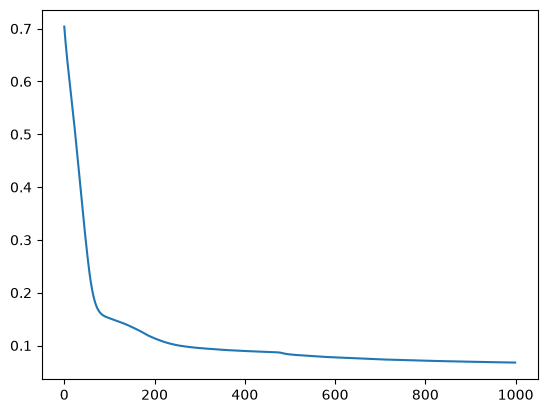

In [23]:
import matplotlib.pyplot as plt
plt.plot(losses)
plt.show()

## **6. 모델 평가**

### **6.1 예측하기**

**Q1. 학습된 모델로 test 데이터에 대한 예측값을 구하세요.**

- test를 할때에는 `torch.no_grad()` 컨텍스트 안에서 추론합니다.

```
model.eval()
with torch.no_grad():
    y_pred = model(X_test_t)
```

- Sigmoid 출력(확률)이 **0.5 이상이면 위조(1)**, 미만이면 진짜(0)으로 분류합니다.

In [24]:
model.eval()

with torch.no_grad():
    y_pred_test = model(X_test_tensor)
    loss_test = criterion(y_pred_test, y_test_tensor)

print(loss_test.item())

0.08350297063589096


**Q2. 예측 결과를 flatten()하여 출력해봅시다.**

- (N,1)의 shape를 가진 tensor를 1차원으로 누르는 함수입니다.

In [25]:
# y_pred_flat = y_pred_test.flatten()
# print(y_pred_flat)
# y_pred_label = (y_pred_test >= 0.5).float().flatten()
# print(y_pred_label)

### **6.2 정확도 평가**

**Q1. 정확도를 활용해 모델 성능을 평가하세요.**

In [26]:
from sklearn.metrics import accuracy_score, confusion_matrix
y_true = y_test_tensor.cpu().numpy().ravel()
y_pred = (y_pred_test >= 0.5).cpu().numpy().astype(int).ravel()
accuracy_score(y_true, y_pred)
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

**Q2. 혼동행렬을 그려 모델 성능을 평가하세요.**

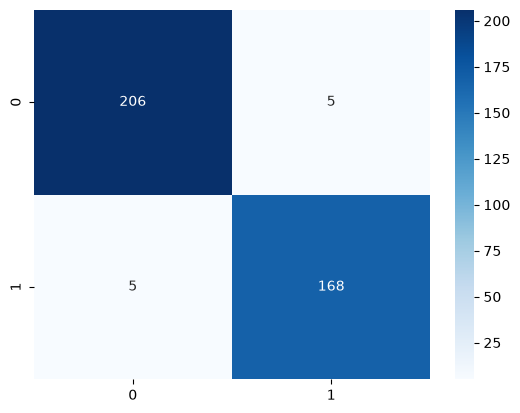

In [ ]:
import seaborn as sns
sns.heatmap(
    cm, annot=True,
    fmt="d", cmap="Blues"
)

plt.show()

## **7. 채점하기**

데이터 전처리 방법과 학습된 모델을 활용하여 미공개 데이터에 대한 분류 예측 결과를 "is_forged" 컬럼에 순서대로 저장하고, 제출합니다.

**미공개 데이터 URL:**

https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/banknote_forgery_submission.csv

In [28]:
submission_df = pd.read_csv("https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/banknote_forgery_submission.csv")

# columns = ["wavelet_variance", "wavelet_skewness", "wavelet_curtosis", "image_entropy"]
submission_df = submission_df[columns]

# scaler = StandardScaler()
submission_df_scaled  = scaler.transform(submission_df)
submission_df_tensor = torch.tensor(submission_df_scaled, dtype=torch.float32)

y_submission = model(submission_df_tensor)
y_submission = np.where((y_submission>0.5), 1, 0)

y_submission = pd.DataFrame(y_submission, columns=['is_forged']).to_csv("output.csv", index=False)
